# Chest X-ray inference (step 1)

Run a **pretrained** chest X-ray model on one image — no training involved. Uses `torchxrayvision`'s DenseNet121, pretrained on public datasets (NIH ChestX-ray14, CheXpert, PadChest, and others).

## Setup

Run this cell once. If you've already installed these, skip it.

## Imports

In [1]:
import sys; print(sys.executable)

e:\projects\new_projects\Radiology_Copilot\.venv\Scripts\python.exe


In [2]:
import torch
import torchxrayvision as xrv
import torchvision.transforms as transforms
import skimage.io
import matplotlib.pyplot as plt

e:\projects\new_projects\Radiology_Copilot\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Set your image path

Point this at a real chest X-ray file (e.g. from the NIH ChestX-ray14 sample set on Kaggle). Don't use real patient data.

In [12]:
IMAGE_PATH = r"E:\projects\new_projects\Radiology_Copilot\archive (4)\chest_xray\chest_xray\test\PNEUMONIA\person1_virus_6.jpeg"

## Preprocessing and inference functions

In [14]:
def load_and_preprocess(image_path: str) -> torch.Tensor:
    """Load a chest X-ray image and preprocess it for the model."""
    img = skimage.io.imread(image_path)

    # torchxrayvision expects single-channel images normalized to [-1024, 1024]
    img = xrv.datasets.normalize(img, 255)
    if img.ndim == 3:
        img = img.mean(axis=2)  # convert to grayscale if RGB
    img = img[None, :, :]  # add channel dimension

    transform = transforms.Compose(
        [xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)]
    )
    img = transform(img)
    return torch.from_numpy(img).unsqueeze(0).float()  # add batch dimension

In [15]:
def analyze_xray(image_path: str) -> dict:
    """Run the pretrained model and return findings as a probability dict."""
    model = xrv.models.DenseNet(weights="densenet121-res224-all")
    model.eval()

    image_tensor = load_and_preprocess(image_path)

    with torch.no_grad():
        outputs = model(image_tensor)

    probabilities = outputs[0].detach().numpy()
    findings = dict(zip(model.pathologies, probabilities))

    # Drop empty-string pathology labels the model doesn't actually predict
    findings = {k: float(v) for k, v in findings.items() if k}
    return dict(sorted(findings.items(), key=lambda kv: kv[1], reverse=True))

## Run inference

In [16]:
results = analyze_xray(IMAGE_PATH)

print("Findings (sorted by probability):")
for finding, probability in results.items():
    print(f"  {finding:20s} {probability:.3f}")

Findings (sorted by probability):
  Lung Opacity         0.825
  Enlarged Cardiomediastinum 0.567
  Effusion             0.556
  Atelectasis          0.552
  Consolidation        0.541
  Mass                 0.532
  Infiltration         0.528
  Cardiomegaly         0.527
  Pneumothorax         0.514
  Nodule               0.507
  Emphysema            0.503
  Fibrosis             0.501
  Pleural_Thickening   0.438
  Pneumonia            0.385
  Edema                0.346
  Fracture             0.236
  Hernia               0.022
  Lung Lesion          0.011


## Visualize

Shows the X-ray alongside its top 5 findings, so you can sanity-check the output against the image.

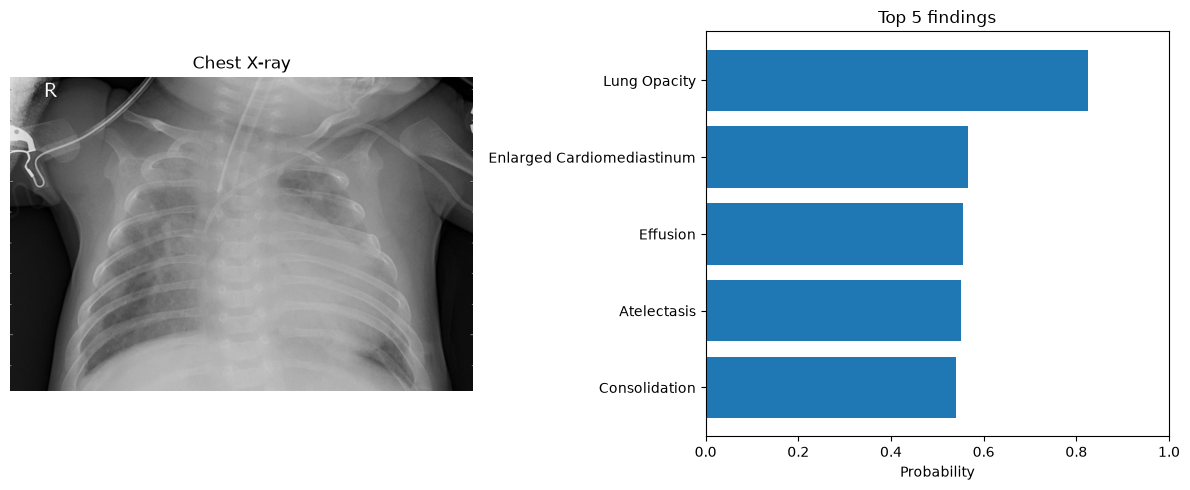

In [17]:
img = skimage.io.imread(IMAGE_PATH)
top5 = dict(list(results.items())[:5])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Chest X-ray")
axes[0].axis("off")

axes[1].barh(list(top5.keys())[::-1], list(top5.values())[::-1])
axes[1].set_xlabel("Probability")
axes[1].set_title("Top 5 findings")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()